# LADI v2 end-to-end semantic-channel scheduling

This notebook is a **measured, reproducible experiment**, not a table of hand-entered results. It downloads official LADI v2 test rows, runs the official pretrained LADI v2 multi-label classifier, applies one declared class-level severity policy to the predicted probabilities, JPEG-encodes the images, and simulates queueing plus a constrained wireless channel.

The proposed method is **Dynamic Semantic-Channel-Aware (DSCA)**. Manually assigned per-image priority is never its input. The static semantic-priority method is retained only as a **label-informed oracle reference** because it uses test labels; test labels are otherwise used only after simulation for evaluation.

### DSCA rule

For queued image $i$ at time $t$, the next-chunk score is

$$S_i(t)=\hat U_i\left(1+\alpha\frac{A_i}{D_i}\right)\left(1+\frac{\beta}{\max(L_i,\epsilon)}\right)\frac{p_i(t)R_i(t)}{B_i(t)}.$$

- $\hat U_i=\sum_c w_c p(c\mid x_i)/\sum_c w_c$: semantic utility inferred by the pretrained classifier and one class-level severity vector $w$.
- $A_i=t-a_i$: queue waiting age; $D_i$ is the image's deadline budget.
- $L_i=d_i-t$: current deadline slack. The reciprocal factor raises urgency as slack disappears.
- $p_i(t)$: predicted success probability for the current modulation/coding point and channel realization.
- $R_i(t)$: current achievable PHY rate in bit/s.
- $B_i(t)$: remaining encoded payload bits, so the final factor rewards useful service per remaining cost.
- $\alpha=0.75$, $\beta=0.35$ s, and $\epsilon=0.05$ s are declared scheduler coefficients, fixed before evaluation.

The simulator uses one 1.5 MHz channel, adaptive discrete spectral efficiencies, AWGN or independent block-Rayleigh fading, stochastic decoding failures, 32 KiB chunks, and up to two retransmissions per chunk. Transmission duration is measured from encoded bits divided by the channel-dependent rate plus protocol overhead; there is no fixed 10 Mb/s assumption.

**Scope/limitations:** this is a link/queue simulator, not an over-the-air deployment. JPEG is the source codec; successfully decoded digital chunks are bit-perfect, so reconstruction quality is JPEG PSNR/SSIM and failed images have no reconstruction. Fading is block-i.i.d., interference and mobility correlation are omitted, severity weights are an explicit experimental policy rather than a universal emergency-management standard, and the official small reference classifier is used for CPU-feasible execution.

In [1]:
from pathlib import Path
import io, json, math, hashlib, platform, sys, time, warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import requests
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.metrics import average_precision_score, f1_score
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from scipy.stats import t as student_t
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if ROOT.name == "Notebooks": ROOT = ROOT.parent
if not (ROOT / "Notebooks").exists():
    raise RuntimeError("Run from the repository root or Notebooks directory")

RUN_ID = "ladi_v2_e2e_semantic_channel_v1"
DATA_DIR = ROOT / "data" / RUN_ID
RESULT_DIR = ROOT / "results" / RUN_ID
FIG_DIR = RESULT_DIR / "figures"
for p in (DATA_DIR, RESULT_DIR, FIG_DIR): p.mkdir(parents=True, exist_ok=True)

CFG = {
    "dataset_id": "MITLL/LADI-v2-dataset",
    "dataset_revision": "5f2dbfe8c466d32edafd1bab847ec5252309acdb",
    "model_id": "MITLL/LADI-v2-classifier-small-reference",
    "model_revision": "6ba5a0300601284bc6b69dddb46c8991a8ac196c",
    "pool_images": 72, "images_per_run": 48,
    "seeds": [2027, 2028, 2029, 2030, 2031],
    "snr_db": [-2, 3, 8, 13], "channels": ["AWGN", "Rayleigh"],
    "bandwidth_hz": 1_500_000, "chunk_bytes": 32 * 1024,
    "max_retransmissions": 2, "jpeg_quality": 55,
    "arrival_rate_per_s": 4.0, "deadline_range_s": [2.5, 7.5],
    "protocol_overhead_s": 0.001, "max_simulation_s": 60.0,
    "dsca_alpha": 0.75, "dsca_beta_s": 0.35, "dsca_epsilon_s": 0.05,
}
LABELS = ["bridges_any","buildings_any","buildings_affected_or_greater",
          "buildings_minor_or_greater","debris_any","flooding_any",
          "flooding_structures","roads_any","roads_damage","trees_any",
          "trees_damage","water_any"]
# One class-level operational policy, applied identically to every image.
SEVERITY = {"bridges_any":0.80,"buildings_any":0.45,"buildings_affected_or_greater":0.75,
            "buildings_minor_or_greater":0.90,"debris_any":0.70,"flooding_any":0.65,
            "flooding_structures":1.00,"roads_any":0.40,"roads_damage":0.85,
            "trees_any":0.25,"trees_damage":0.55,"water_any":0.30}
SCHEDULERS = ["FCFS","SPT","Round Robin","EDF","Static semantic oracle","Weighted-SPT","DSCA (proposed)"]

print(json.dumps(CFG, indent=2))
print({"python": sys.version.split()[0], "torch": torch.__version__, "device": "cuda" if torch.cuda.is_available() else "cpu", "platform": platform.platform()})

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "dataset_id": "MITLL/LADI-v2-dataset",
  "dataset_revision": "5f2dbfe8c466d32edafd1bab847ec5252309acdb",
  "model_id": "MITLL/LADI-v2-classifier-small-reference",
  "model_revision": "6ba5a0300601284bc6b69dddb46c8991a8ac196c",
  "pool_images": 72,
  "images_per_run": 48,
  "seeds": [
    2027,
    2028,
    2029,
    2030,
    2031
  ],
  "snr_db": [
    -2,
    3,
    8,
    13
  ],
  "channels": [
    "AWGN",
    "Rayleigh"
  ],
  "bandwidth_hz": 1500000,
  "chunk_bytes": 32768,
  "max_retransmissions": 2,
  "jpeg_quality": 55,
  "arrival_rate_per_s": 4.0,
  "deadline_range_s": [
    2.5,
    7.5
  ],
  "protocol_overhead_s": 0.001,
  "max_simulation_s": 60.0,
  "dsca_alpha": 0.75,
  "dsca_beta_s": 0.35,
  "dsca_epsilon_s": 0.05
}
{'python': '3.13.4', 'torch': '2.12.1+cpu', 'device': 'cpu', 'platform': 'Windows-11-10.0.26200-SP0'}


## Acquire a balanced official test-image pool

The pool is selected deterministically from official test rows using only label metadata for stratified coverage. Those labels are never passed to the classifier or DSCA. Image bytes, labels, model and dataset revisions are recorded for provenance.

In [2]:
api = requests.get(f"https://huggingface.co/api/datasets/{CFG['dataset_id']}", timeout=60)
api.raise_for_status()
if api.json()["sha"] != CFG["dataset_revision"]:
    raise RuntimeError(f"Dataset revision drift: {api.json()['sha']}")

candidates = []
for offset in range(0, 900, 100):
    url = ("https://datasets-server.huggingface.co/rows?dataset=MITLL%2FLADI-v2-dataset"
           f"&config=default&split=test&offset={offset}&length=100")
    block = requests.get(url, timeout=120); block.raise_for_status()
    for obj in block.json()["rows"]:
        row = obj["row"]
        positives = [x for x in LABELS if bool(row[x])]
        if positives:
            candidates.append((obj["row_idx"], row, positives))

# Greedy multilabel balancing with a fixed tie break.
counts = defaultdict(int); chosen = []; remaining = list(candidates)
while len(chosen) < CFG["pool_images"]:
    best = max(remaining, key=lambda z: (sum(1.0 / (1 + counts[x]) for x in z[2]), -z[0]))
    chosen.append(best); remaining.remove(best)
    for x in best[2]: counts[x] += 1

records = []
for row_idx, row, positives in chosen:
    original_path = DATA_DIR / f"test_{row_idx:04d}.jpg"
    jpeg_path = DATA_DIR / f"test_{row_idx:04d}_q{CFG['jpeg_quality']}.jpg"
    if not original_path.exists():
        rr = requests.get(row["image"]["src"], timeout=180); rr.raise_for_status()
        with Image.open(io.BytesIO(rr.content)) as im:
            im.convert("RGB").save(original_path, quality=95, optimize=True)
    with Image.open(original_path) as im:
        rgb = im.convert("RGB")
        if not jpeg_path.exists(): rgb.save(jpeg_path, quality=CFG["jpeg_quality"], optimize=True)
        orig = np.asarray(rgb)
    rec = np.asarray(Image.open(jpeg_path).convert("RGB"))
    psnr = peak_signal_noise_ratio(orig, rec, data_range=255)
    ssim = structural_similarity(orig, rec, channel_axis=2, data_range=255)
    truth = {x:int(x in positives) for x in LABELS}
    records.append({"item_id":f"T{row_idx:04d}","row_idx":row_idx,"positive_labels":"|".join(positives),
                    **truth,"original_path":str(original_path),"encoded_path":str(jpeg_path),
                    "source_bytes":original_path.stat().st_size,"encoded_bytes":jpeg_path.stat().st_size,
                    "jpeg_psnr_db":psnr,"jpeg_ssim":ssim})

manifest = pd.DataFrame(records)
manifest.to_csv(RESULT_DIR / "image_manifest.csv", index=False)
assert len(manifest) == CFG["pool_images"] and manifest.row_idx.nunique() == len(manifest)
print("Pool label counts:", manifest[LABELS].sum().to_dict())
display(manifest[["item_id","positive_labels","encoded_bytes","jpeg_psnr_db","jpeg_ssim"]].head())

Pool label counts: {'bridges_any': 19, 'buildings_any': 65, 'buildings_affected_or_greater': 37, 'buildings_minor_or_greater': 22, 'debris_any': 27, 'flooding_any': 19, 'flooding_structures': 6, 'roads_any': 71, 'roads_damage': 5, 'trees_any': 72, 'trees_damage': 40, 'water_any': 38}


,item_id,positive_labels,encoded_bytes,jpeg_psnr_db,jpeg_ssim
0,T0899,bridges_any|buildings_any|buildings_affected_o...,280664,35.618697,0.952360
1,T0123,buildings_any|buildings_affected_or_greater|bu...,159113,39.053998,0.960482
2,T0462,buildings_any|buildings_affected_or_greater|fl...,192031,39.552380,0.969507
3,T0166,bridges_any|buildings_any|buildings_affected_o...,156766,40.765985,0.970278
4,T0000,buildings_any|buildings_affected_or_greater|bu...,395711,32.897812,0.949782


## Pretrained LADI v2 inference and semantic utility

Both original and transmitted JPEG images are inferred by the pinned official model. Scheduling sees only the original-image probabilities. The compressed-image probabilities are reserved for post-transmission evaluation. Raw probabilities are saved.

In [3]:
processor = AutoImageProcessor.from_pretrained(CFG["model_id"], revision=CFG["model_revision"], use_fast=False)
model = AutoModelForImageClassification.from_pretrained(CFG["model_id"], revision=CFG["model_revision"])
model.eval(); device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); model.to(device)
model_labels = [model.config.id2label[i] for i in range(len(model.config.id2label))]
assert model_labels == LABELS and model.config.problem_type == "multi_label_classification"

cache_path = RESULT_DIR / "classifier_probabilities.csv"
if cache_path.exists():
    probs_df = pd.read_csv(cache_path)
    expected = {f"orig_p_{x}" for x in LABELS} | {f"jpeg_p_{x}" for x in LABELS}
    if len(probs_df) != len(manifest) or not expected.issubset(probs_df.columns):
        raise RuntimeError("Inference cache is incompatible; remove this run-specific cache and rerun")
else:
    out = []
    for start in range(0, len(manifest), 8):
        batch = manifest.iloc[start:start+8]
        original_images = [Image.open(x).convert("RGB") for x in batch.original_path]
        jpeg_images = [Image.open(x).convert("RGB") for x in batch.encoded_path]
        with torch.inference_mode():
            op = torch.sigmoid(model(**processor(images=original_images, return_tensors="pt").to(device)).logits).cpu().numpy()
            jp = torch.sigmoid(model(**processor(images=jpeg_images, return_tensors="pt").to(device)).logits).cpu().numpy()
        for (_, r), a, b in zip(batch.iterrows(), op, jp):
            out.append({"item_id":r.item_id, **{f"orig_p_{x}":float(v) for x,v in zip(LABELS,a)},
                        **{f"jpeg_p_{x}":float(v) for x,v in zip(LABELS,b)}})
    probs_df = pd.DataFrame(out); probs_df.to_csv(cache_path, index=False)

items = manifest.merge(probs_df, on="item_id", validate="one_to_one")
w = np.array([SEVERITY[x] for x in LABELS], dtype=float)
items["predicted_utility"] = items[[f"orig_p_{x}" for x in LABELS]].to_numpy().dot(w) / w.sum()
items["true_utility"] = items[LABELS].to_numpy().dot(w) / w.sum()
items["primary_class"] = [LABELS[i] for i in np.argmax(items[LABELS].to_numpy()*w, axis=1)]

y = items[LABELS].to_numpy(); p0 = items[[f"orig_p_{x}" for x in LABELS]].to_numpy(); pj = items[[f"jpeg_p_{x}" for x in LABELS]].to_numpy()
classifier_check = pd.DataFrame([
    {"representation":"original","micro_f1_at_0.5":f1_score(y.ravel(),(p0>=.5).ravel()),"macro_map":average_precision_score(y,p0,average="macro")},
    {"representation":f"jpeg_q{CFG['jpeg_quality']}","micro_f1_at_0.5":f1_score(y.ravel(),(pj>=.5).ravel()),"macro_map":average_precision_score(y,pj,average="macro")}
])
classifier_check.to_csv(RESULT_DIR / "classifier_quality_check.csv", index=False)
items.to_csv(RESULT_DIR / "inference_enriched_manifest.csv", index=False)
display(classifier_check)
display(items[["item_id","positive_labels","predicted_utility","true_utility"]].head())

,representation,micro_f1_at_0.5,macro_map
0,original,0.790503,0.773217
1,jpeg_q55,0.792768,0.769340


,item_id,positive_labels,predicted_utility,true_utility
0,T0899,bridges_any|buildings_any|buildings_affected_o...,0.358547,0.789474
1,T0123,buildings_any|buildings_affected_or_greater|bu...,0.160658,0.638158
2,T0462,buildings_any|buildings_affected_or_greater|fl...,0.144059,0.684211
3,T0166,bridges_any|buildings_any|buildings_affected_o...,0.251398,0.605263
4,T0000,buildings_any|buildings_affected_or_greater|bu...,0.236812,0.526316


## Channel and scheduler simulation

Adaptive spectral efficiencies `[0.5, 1, 2, 3, 4]` bit/s/Hz use SNR thresholds `[-2, 2, 7, 12, 17]` dB. Conditional block-error probability is a logistic waterfall around the chosen threshold. Rayleigh fading multiplies instantaneous SNR by an exponential power gain. Deterministic hash-derived random draws make each image/chunk/attempt reproducible and shared across schedulers where the same event is reached.

Baselines: FCFS; shortest remaining processing time (SPT); chunk-level Round Robin; earliest deadline first (EDF); static semantic oracle using test-label utility (oracle semantic input, but not a globally optimal schedule); Weighted-SPT using inferred utility per remaining nominal cost. DSCA alone jointly adapts to utility, slack, age, remaining cost, and current link state.

In [4]:
MCS_EFF = np.array([0.5,1.0,2.0,3.0,4.0]); MCS_THR = np.array([-2.0,2.0,7.0,12.0,17.0])

def stable_uniform(*parts):
    h = hashlib.sha256("|".join(map(str,parts)).encode()).digest()
    return (int.from_bytes(h[:8],"big") + 0.5) / 2**64

def channel_state(base_snr, channel, seed, item_id, chunk_idx, attempt):
    ufade = stable_uniform("fade",seed,channel,base_snr,item_id,chunk_idx,attempt)
    fade = 1.0 if channel == "AWGN" else -math.log(max(1e-12,1-ufade))
    inst_db = base_snr + 10*math.log10(max(fade,1e-8))
    valid = np.where(inst_db >= MCS_THR)[0]
    idx = int(valid[-1]) if len(valid) else 0
    rate = CFG["bandwidth_hz"] * MCS_EFF[idx]
    p_success = 1.0 / (1.0 + math.exp(-1.35*(inst_db-MCS_THR[idx])))
    return inst_db, rate, p_success

def choose(queue, state, scheduler, now, seed, channel, snr):
    if scheduler == "FCFS": return min(queue, key=lambda i:(state[i]["arrival"],i))
    if scheduler == "SPT": return min(queue, key=lambda i:(state[i]["remaining_bits"],state[i]["arrival"]))
    if scheduler == "Round Robin": return min(queue, key=lambda i:(state[i]["rr_ticket"],state[i]["arrival"]))
    if scheduler == "EDF": return min(queue, key=lambda i:(state[i]["deadline"],state[i]["arrival"]))
    if scheduler == "Static semantic oracle": return max(queue, key=lambda i:(state[i]["true_utility"],-state[i]["arrival"]))
    if scheduler == "Weighted-SPT": return max(queue, key=lambda i:(state[i]["predicted_utility"]/max(state[i]["remaining_bits"],1),-state[i]["arrival"]))
    def dsca(i):
        s=state[i]; chunk=s["chunks_ok"]; attempt=s["chunk_attempt"]
        _,rate,ps=channel_state(snr,channel,seed,i,chunk,attempt)
        age=max(0,now-s["arrival"]); slack=s["deadline"]-now; budget=s["deadline"]-s["arrival"]
        return (s["predicted_utility"]*(1+CFG["dsca_alpha"]*age/max(budget,1e-6)) *
                (1+CFG["dsca_beta_s"]/max(slack,CFG["dsca_epsilon_s"])) * ps*rate/max(s["remaining_bits"],1))
    return max(queue, key=lambda i:(dsca(i),-state[i]["arrival"]))

def simulate(base, scheduler, channel, snr, seed):
    rng=np.random.default_rng(seed); pick=rng.choice(len(base),CFG["images_per_run"],replace=False)
    run=base.iloc[pick].copy().reset_index(drop=True)
    arrivals=np.cumsum(rng.exponential(1/CFG["arrival_rate_per_s"],len(run))); arrivals-=arrivals.min()
    budgets=rng.uniform(*CFG["deadline_range_s"],len(run))
    state={}
    for k,r in run.iterrows():
        bits=int(r.encoded_bytes)*8
        state[r.item_id]={"arrival":float(arrivals[k]),"deadline":float(arrivals[k]+budgets[k]),"budget":float(budgets[k]),
          "remaining_bits":bits,"payload_bits":bits,"chunks_ok":0,"chunk_attempt":0,"retransmissions":0,
          "attempted_bits":0,"airtime":0.0,"finish":np.nan,"status":"queued","rr_ticket":k,
          "predicted_utility":float(r.predicted_utility),"true_utility":float(r.true_utility),
          "primary_class":r.primary_class,"jpeg_psnr_db":float(r.jpeg_psnr_db),"jpeg_ssim":float(r.jpeg_ssim),"row":r}
    now=0.0; rr_counter=len(run); events=[]
    while now < CFG["max_simulation_s"]:
        # Operational expiry: once a deadline passes, stale imagery is removed
        # instead of consuming scarce radio resources that can no longer earn utility.
        for s in state.values():
            if s["status"]=="queued" and s["arrival"]<=now and s["deadline"]<now:
                s["status"]="expired"; s["finish"]=now
        queue=[i for i,s in state.items() if s["status"]=="queued" and s["arrival"]<=now]
        if not queue:
            future=[s["arrival"] for s in state.values() if s["status"]=="queued" and s["arrival"]>now]
            if not future: break
            now=min(future); continue
        i=choose(queue,state,scheduler,now,seed,channel,snr); s=state[i]
        chunk_bits=min(CFG["chunk_bytes"]*8,s["remaining_bits"])
        inst_db,rate,ps=channel_state(snr,channel,seed,i,s["chunks_ok"],s["chunk_attempt"])
        duration=chunk_bits/rate+CFG["protocol_overhead_s"]
        success=stable_uniform("decode",seed,channel,snr,i,s["chunks_ok"],s["chunk_attempt"]) < ps
        start=now; now+=duration; s["airtime"]+=duration; s["attempted_bits"]+=chunk_bits
        events.append({"scheduler":scheduler,"channel":channel,"snr_db":snr,"seed":seed,"item_id":i,
                       "start_s":start,"end_s":now,"instantaneous_snr_db":inst_db,"rate_bps":rate,
                       "success_probability":ps,"decoded":success,"chunk_index":s["chunks_ok"],"attempt":s["chunk_attempt"]})
        if success:
            s["remaining_bits"]-=chunk_bits; s["chunks_ok"]+=1; s["chunk_attempt"]=0
            if s["remaining_bits"]<=0: s["status"]="delivered"; s["finish"]=now
        else:
            if s["chunk_attempt"] < CFG["max_retransmissions"]:
                s["chunk_attempt"]+=1; s["retransmissions"]+=1
            else: s["status"]="dropped"; s["finish"]=now
        if scheduler=="Round Robin": s["rr_ticket"]=rr_counter; rr_counter+=1
    for s in state.values():
        if s["status"]=="queued": s["status"]="timeout"; s["finish"]=CFG["max_simulation_s"]
    rows=[]
    for i,s in state.items():
        delivered=s["status"]=="delivered"; ontime=delivered and s["finish"]<=s["deadline"]
        r=s["row"]
        rows.append({"scheduler":scheduler,"channel":channel,"snr_db":snr,"seed":seed,"item_id":i,
          "arrival_s":s["arrival"],"deadline_s":s["deadline"],"finish_s":s["finish"],
          "latency_s":s["finish"]-s["arrival"],"status":s["status"],"delivered":delivered,"on_time":ontime,
          "predicted_utility":s["predicted_utility"],"true_utility":s["true_utility"],
          "utility_delivered_before_deadline":s["true_utility"]*ontime,"payload_bits":s["payload_bits"],
          "attempted_bits":s["attempted_bits"],"airtime_s":s["airtime"],"retransmissions":s["retransmissions"],
          "primary_class":s["primary_class"],"jpeg_psnr_db":s["jpeg_psnr_db"] if delivered else np.nan,
          "jpeg_ssim":s["jpeg_ssim"] if delivered else np.nan,
          **{x:int(r[x]) for x in LABELS}, **{f"post_p_{x}":float(r[f'jpeg_p_{x}']) if delivered else np.nan for x in LABELS}})
    return pd.DataFrame(rows),pd.DataFrame(events)

raw=[]; event=[]
for channel in CFG["channels"]:
  for snr in CFG["snr_db"]:
    for seed in CFG["seeds"]:
      for scheduler in SCHEDULERS:
        a,b=simulate(items,scheduler,channel,snr,seed); raw.append(a); event.append(b)
raw=pd.concat(raw,ignore_index=True); events=pd.concat(event,ignore_index=True)
raw.to_csv(RESULT_DIR/"raw_per_image_results.csv",index=False)
events.to_csv(RESULT_DIR/"raw_transmission_events.csv",index=False)
print(f"Saved {len(raw):,} per-image rows and {len(events):,} chunk-attempt events")

Saved 13,440 per-image rows and 38,579 chunk-attempt events


## Metrics, confidence intervals, and best-method audit

Utility is true policy utility delivered on time (labels are used here only for evaluation). Fairness is Jain's index over per-primary-class on-time delivery rates. Post-transmission F1/mAP use only successfully delivered JPEGs; failed packets contribute no classifier output. Confidence intervals are two-sided 95% Student-t intervals across independent seeds.

In [5]:
def jain(x):
    x=np.asarray(x,float); return (x.sum()**2)/(len(x)*(x*x).sum()) if len(x) and (x*x).sum()>0 else np.nan
def summarize(g):
    delivered=g[g.delivered]; y=delivered[LABELS].to_numpy(); p=delivered[[f"post_p_{x}" for x in LABELS]].to_numpy()
    class_rates=g.groupby("primary_class").on_time.mean()
    active_airtime=max(g.airtime_s.sum(),1e-9)
    return pd.Series({
      "semantic_utility_on_time":g.utility_delivered_before_deadline.sum(),
      "deadline_miss_rate":1-g.on_time.mean(),"mean_latency_s":delivered.latency_s.mean(),"p95_latency_s":delivered.latency_s.quantile(.95),
      "throughput_mbps":delivered.payload_bits.sum()/active_airtime/1e6,"fairness_jain":jain(class_rates),
      "airtime_s":g.airtime_s.sum(),"resource_efficiency":g.payload_bits.where(g.delivered,0).sum()/max(g.attempted_bits.sum(),1),
      "successful_delivery_rate":g.delivered.mean(),"mean_psnr_db":delivered.jpeg_psnr_db.mean(),"mean_ssim":delivered.jpeg_ssim.mean(),
      "post_micro_f1":f1_score(y.ravel(),(p>=.5).ravel(),zero_division=0) if len(delivered) else np.nan,
      "post_macro_map":average_precision_score(y,p,average="macro") if len(delivered)>1 else np.nan,
      "retransmissions":g.retransmissions.sum()})

run_summary=raw.groupby(["scheduler","channel","snr_db","seed"],sort=False).apply(summarize,include_groups=False).reset_index()
run_summary.to_csv(RESULT_DIR/"per_run_summary.csv",index=False)
metric_cols=[x for x in run_summary.columns if x not in ["scheduler","channel","snr_db","seed"]]
agg=run_summary.groupby(["scheduler","channel","snr_db"])[metric_cols].agg(["mean","std","count"])
out=[]
for idx,row in agg.iterrows():
    rec=dict(zip(["scheduler","channel","snr_db"],idx))
    for m in metric_cols:
        mean,std,n=row[(m,"mean")],row[(m,"std")],row[(m,"count")]
        half=student_t.ppf(.975,n-1)*std/math.sqrt(n) if n>1 else np.nan
        low,high=mean-half,mean+half
        if m in {"deadline_miss_rate","fairness_jain","resource_efficiency","successful_delivery_rate","mean_ssim","post_micro_f1","post_macro_map"}:
            low,high=max(0,low),min(1,high)
        elif m in {"semantic_utility_on_time","mean_latency_s","p95_latency_s","throughput_mbps","airtime_s","mean_psnr_db","retransmissions"}:
            low=max(0,low)
        rec.update({f"{m}_mean":mean,f"{m}_ci95_low":low,f"{m}_ci95_high":high})
    out.append(rec)
aggregate=pd.DataFrame(out); aggregate.to_csv(RESULT_DIR/"aggregate_summary_with_ci.csv",index=False)

directions={"semantic_utility_on_time":"max","deadline_miss_rate":"min","mean_latency_s":"min","p95_latency_s":"min",
 "throughput_mbps":"max","fairness_jain":"max","airtime_s":"min","resource_efficiency":"max",
 "successful_delivery_rate":"max","mean_psnr_db":"max","mean_ssim":"max","post_micro_f1":"max","post_macro_map":"max","retransmissions":"min"}
best=[]
for (ch,snr),g in aggregate.groupby(["channel","snr_db"]):
  for m,d in directions.items():
    col=f"{m}_mean"; v=g[col].min() if d=="min" else g[col].max()
    best.append({"channel":ch,"snr_db":snr,"metric":m,"direction":d,"best_value":v,
                 "best_scheduler":" | ".join(g.loc[np.isclose(g[col],v,equal_nan=False),"scheduler"])})
best=pd.DataFrame(best); best.to_csv(RESULT_DIR/"best_method_per_metric.csv",index=False)
display(aggregate[["scheduler","channel","snr_db","semantic_utility_on_time_mean","semantic_utility_on_time_ci95_low","semantic_utility_on_time_ci95_high","deadline_miss_rate_mean","p95_latency_s_mean","fairness_jain_mean","successful_delivery_rate_mean"]].round(4))

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all

... (6 outputs left out)

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all

C:\Users\Nandini.P\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


,scheduler,channel,snr_db,semantic_utility_on_time_mean,semantic_utility_on_time_ci95_low,semantic_utility_on_time_ci95_high,deadline_miss_rate_mean,p95_latency_s_mean,fairness_jain_mean,successful_delivery_rate_mean
0,DSCA (proposed),AWGN,-2,0.4171,0.0000,0.8642,0.9708,4.1117,0.1683,0.0375
1,DSCA (proposed),AWGN,3,2.3132,1.5771,3.0492,0.8625,4.5537,0.4173,0.1417
2,DSCA (proposed),AWGN,8,5.4789,4.1288,6.8291,0.7250,4.6668,0.5592,0.2792
3,DSCA (proposed),AWGN,13,8.5421,7.4672,9.6171,0.5708,5.9263,0.6608,0.4333
4,DSCA (proposed),Rayleigh,-2,0.1289,0.0000,0.4870,0.9917,3.5535,0.2462,0.0083
5,DSCA (proposed),Rayleigh,3,0.8684,0.0000,2.0673,0.9542,3.4928,0.3205,0.0458
6,DSCA (proposed),Rayleigh,8,2.3434,1.2851,3.4018,0.8708,4.8852,0.4305,0.1333
7,DSCA (proposed),Rayleigh,13,4.8434,3.5101,6.1767,0.7500,4.8946,0.5649,0.2583
8,EDF,AWGN,-2,0.0566,0.0000,0.2137,0.9958,2.1642,0.1250,0.0042
9,EDF,AWGN,3,0.9053,0.2584,1.5521,0.9542,4.2854,0.2249,0.0500


## Figures

All error bars are 95% confidence intervals across seeds. Every figure is saved as PNG and embedded below.

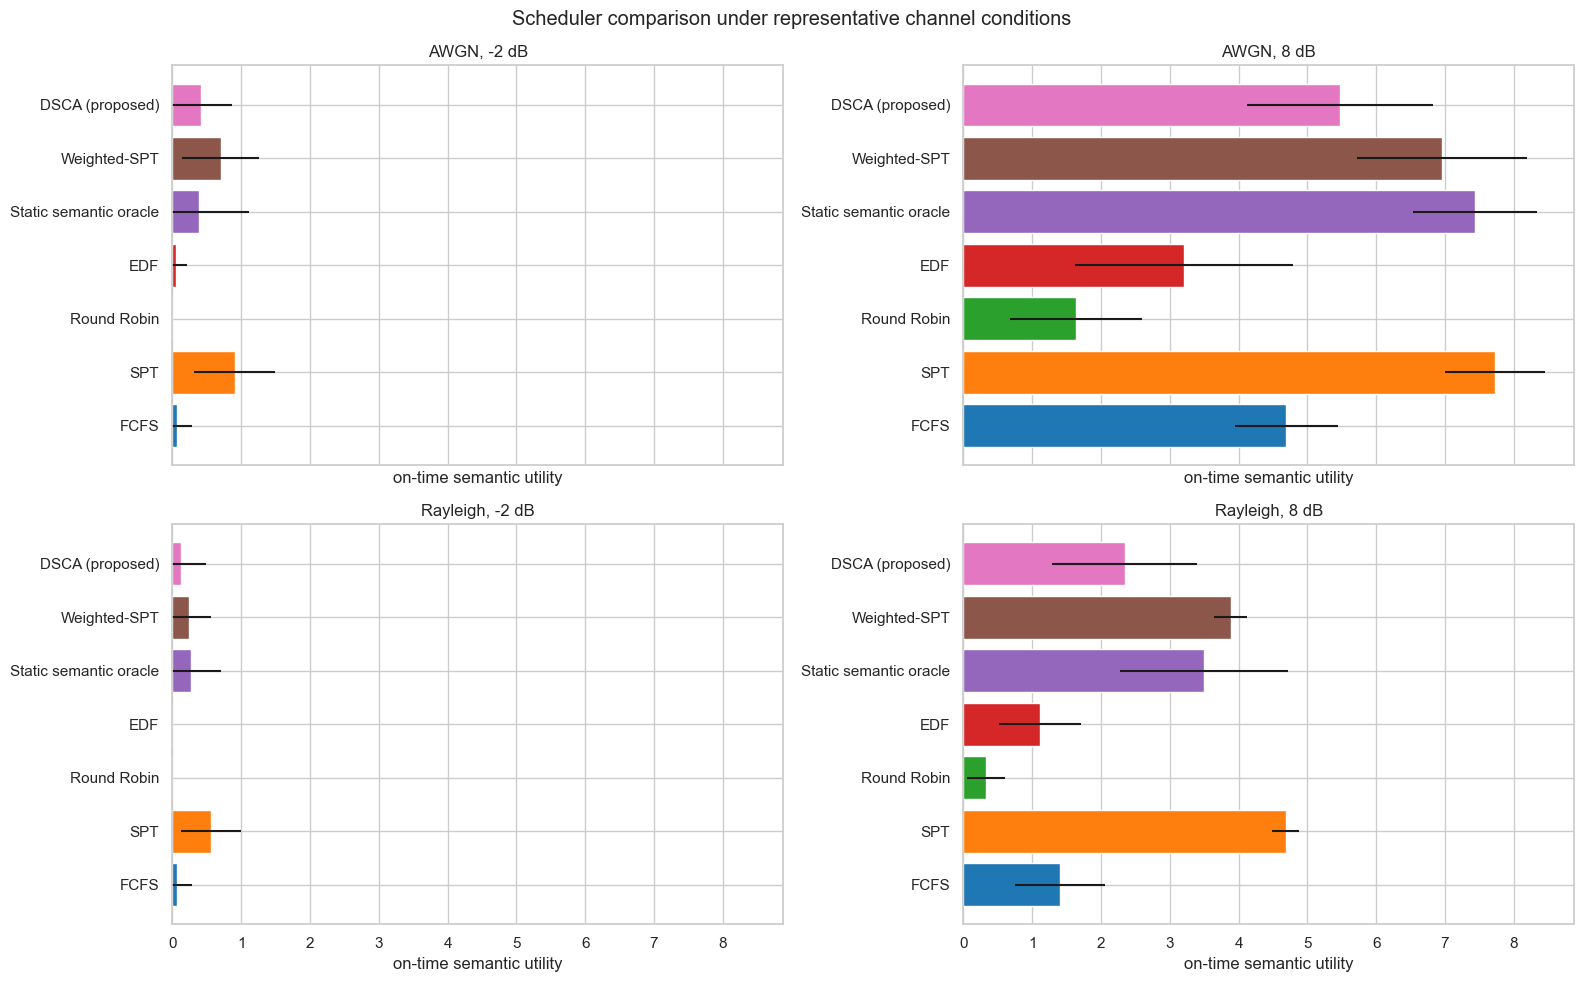

In [6]:
palette=dict(zip(SCHEDULERS,sns.color_palette("tab10",len(SCHEDULERS))))
def err(metric):
    return np.vstack([aggregate[f"{metric}_mean"]-aggregate[f"{metric}_ci95_low"],aggregate[f"{metric}_ci95_high"]-aggregate[f"{metric}_mean"]])

fig,axs=plt.subplots(2,2,figsize=(16,10),sharex=True)
for ax,(ch,snr) in zip(axs.ravel(),[(c,s) for c in CFG["channels"] for s in (-2,8)]):
    g=aggregate[(aggregate.channel==ch)&(aggregate.snr_db==snr)].set_index("scheduler").loc[SCHEDULERS].reset_index()
    ax.barh(g.scheduler,g.semantic_utility_on_time_mean,xerr=np.vstack([g.semantic_utility_on_time_mean-g.semantic_utility_on_time_ci95_low,g.semantic_utility_on_time_ci95_high-g.semantic_utility_on_time_mean]),color=[palette[x] for x in g.scheduler])
    ax.set_title(f"{ch}, {snr} dB"); ax.set_xlabel("on-time semantic utility")
fig.suptitle("Scheduler comparison under representative channel conditions"); fig.tight_layout(); fig.savefig(FIG_DIR/"scheduler_comparison_bars.png",dpi=170,bbox_inches="tight"); plt.show()

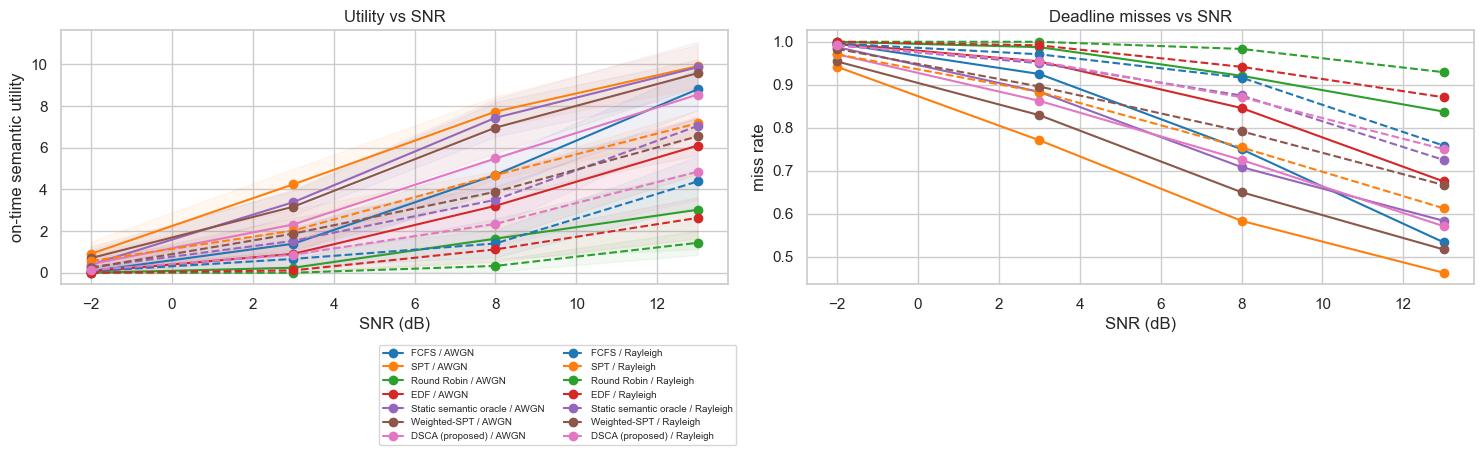

In [7]:
fig,axs=plt.subplots(1,2,figsize=(15,5))
for ch,ls in zip(CFG["channels"],["-","--"]):
  for sched in SCHEDULERS:
    g=aggregate[(aggregate.channel==ch)&(aggregate.scheduler==sched)].sort_values("snr_db")
    axs[0].plot(g.snr_db,g.semantic_utility_on_time_mean,marker="o",ls=ls,color=palette[sched],label=f"{sched} / {ch}")
    axs[0].fill_between(g.snr_db,g.semantic_utility_on_time_ci95_low,g.semantic_utility_on_time_ci95_high,color=palette[sched],alpha=.06)
    axs[1].plot(g.snr_db,g.deadline_miss_rate_mean,marker="o",ls=ls,color=palette[sched])
axs[0].set(title="Utility vs SNR",xlabel="SNR (dB)",ylabel="on-time semantic utility"); axs[1].set(title="Deadline misses vs SNR",xlabel="SNR (dB)",ylabel="miss rate")
axs[0].legend(fontsize=7,ncol=2,bbox_to_anchor=(1.02,-.22)); fig.tight_layout(); fig.savefig(FIG_DIR/"utility_deadline_vs_snr.png",dpi=170,bbox_inches="tight"); plt.show()

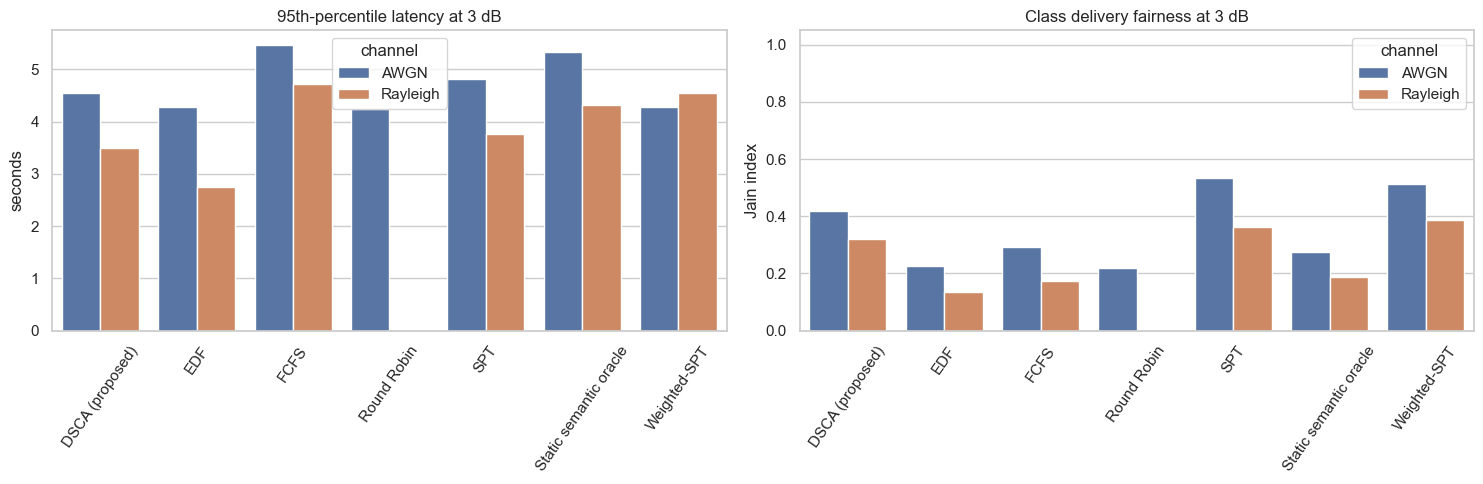

In [8]:
fig,axs=plt.subplots(1,2,figsize=(15,5))
g=aggregate[aggregate.snr_db==3]
sns.barplot(data=g,x="scheduler",y="p95_latency_s_mean",hue="channel",ax=axs[0]); axs[0].tick_params(axis="x",rotation=55); axs[0].set(title="95th-percentile latency at 3 dB",xlabel="",ylabel="seconds")
sns.barplot(data=g,x="scheduler",y="fairness_jain_mean",hue="channel",ax=axs[1]); axs[1].tick_params(axis="x",rotation=55); axs[1].set(title="Class delivery fairness at 3 dB",xlabel="",ylabel="Jain index",ylim=(0,1.05))
fig.tight_layout(); fig.savefig(FIG_DIR/"latency_fairness.png",dpi=170,bbox_inches="tight"); plt.show()

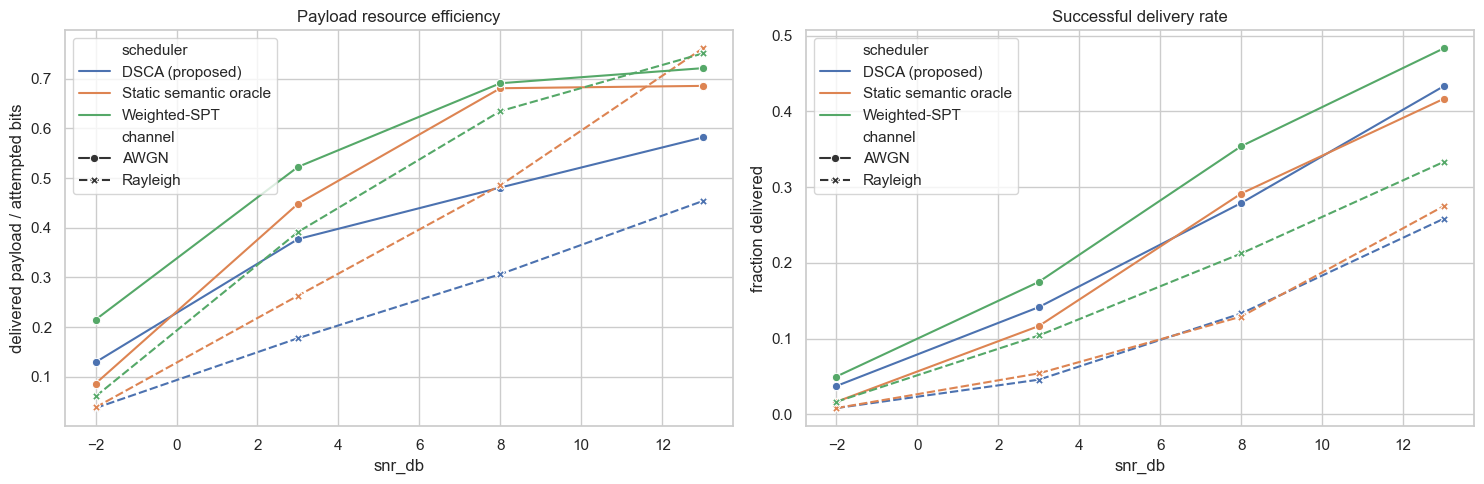

In [9]:
fig,axs=plt.subplots(1,2,figsize=(15,5))
g=aggregate[aggregate.scheduler.isin(["Static semantic oracle","Weighted-SPT","DSCA (proposed)"])]
sns.lineplot(data=g,x="snr_db",y="resource_efficiency_mean",hue="scheduler",style="channel",markers=True,dashes=True,ax=axs[0])
sns.lineplot(data=g,x="snr_db",y="successful_delivery_rate_mean",hue="scheduler",style="channel",markers=True,dashes=True,ax=axs[1])
axs[0].set(title="Payload resource efficiency",ylabel="delivered payload / attempted bits"); axs[1].set(title="Successful delivery rate",ylabel="fraction delivered")
fig.tight_layout(); fig.savefig(FIG_DIR/"resource_delivery.png",dpi=170,bbox_inches="tight"); plt.show()

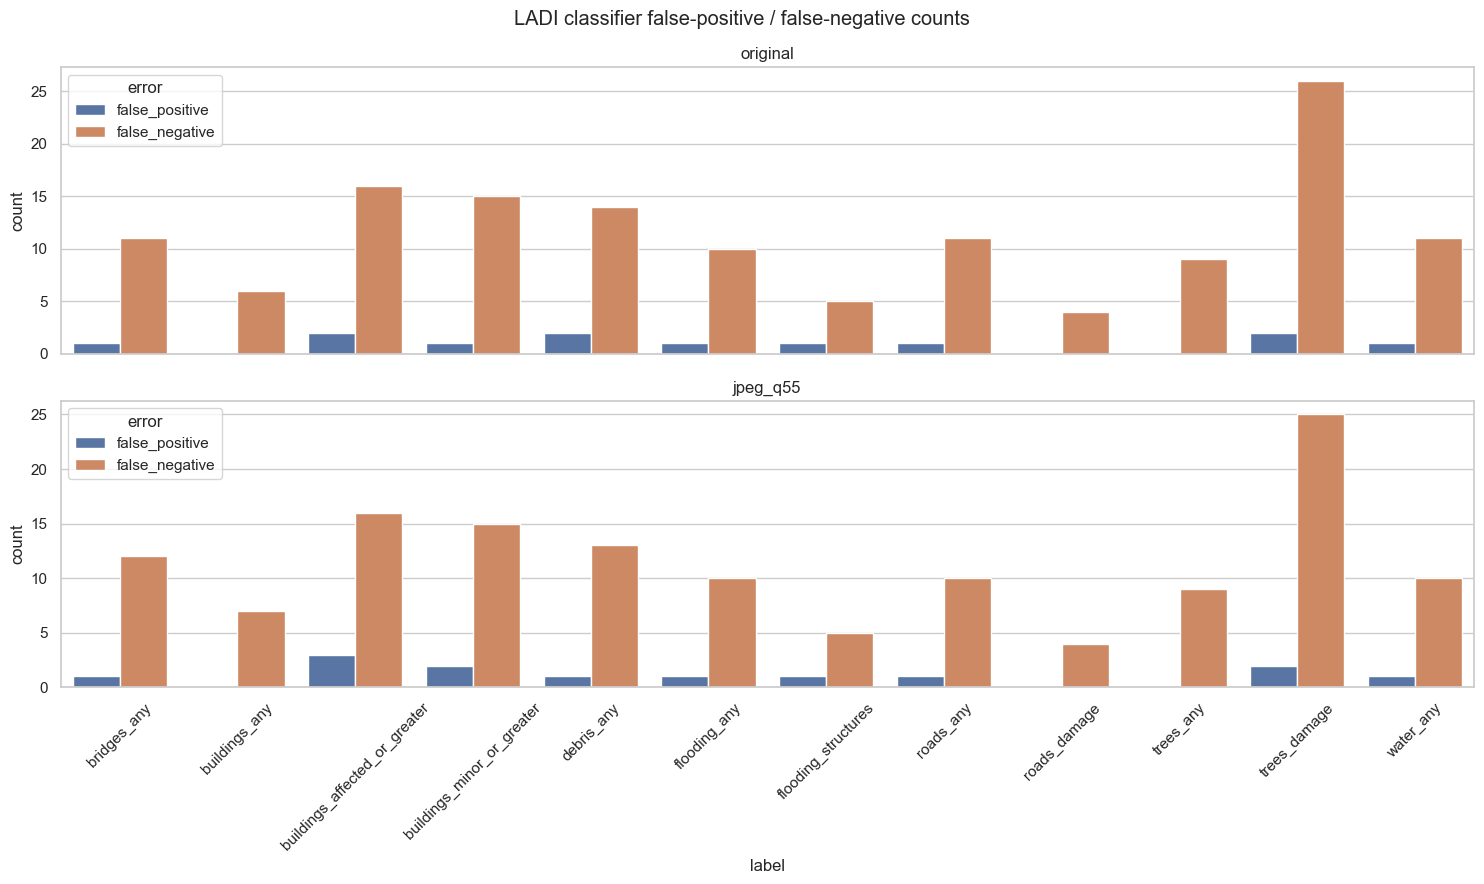

In [10]:
# Classifier error profile before/after JPEG on the entire pool (not scheduler-selected).
truth=items[LABELS].to_numpy().astype(bool); po=items[[f"orig_p_{x}" for x in LABELS]].to_numpy()>=.5; pj=items[[f"jpeg_p_{x}" for x in LABELS]].to_numpy()>=.5
err_rows=[]
for rep,pred in [("original",po),(f"jpeg_q{CFG['jpeg_quality']}",pj)]:
  for j,label in enumerate(LABELS): err_rows.append({"representation":rep,"label":label,"false_positive":int((pred[:,j]&~truth[:,j]).sum()),"false_negative":int((~pred[:,j]&truth[:,j]).sum())})
errors=pd.DataFrame(err_rows); errors.to_csv(RESULT_DIR/"classifier_error_counts.csv",index=False)
plot=errors.melt(id_vars=["representation","label"],var_name="error",value_name="count")
fig,axs=plt.subplots(2,1,figsize=(15,9),sharex=True)
for ax,(rep,g) in zip(axs,plot.groupby("representation",sort=False)):
    sns.barplot(data=g,x="label",y="count",hue="error",ax=ax); ax.set_title(rep); ax.tick_params(axis="x",rotation=45)
fig.suptitle("LADI classifier false-positive / false-negative counts"); fig.tight_layout(); fig.savefig(FIG_DIR/"classifier_errors.png",dpi=170,bbox_inches="tight"); plt.show()

## Measured interpretation (generated from saved results)

In [11]:
overall=run_summary.groupby("scheduler")[metric_cols].mean()
key=["semantic_utility_on_time","deadline_miss_rate","mean_latency_s","p95_latency_s","throughput_mbps","fairness_jain","resource_efficiency","successful_delivery_rate","post_micro_f1"]
display(overall[key].sort_values("semantic_utility_on_time",ascending=False).round(4))

winner_utility=overall.semantic_utility_on_time.idxmax(); winner_miss=overall.deadline_miss_rate.idxmin(); winner_fair=overall.fairness_jain.idxmax()
dsca=overall.loc["DSCA (proposed)"]; oracle=overall.loc["Static semantic oracle"]
interpretation=(f"Across all measured channel/SNR/seed combinations, {winner_utility} had the highest mean on-time semantic utility; "
 f"{winner_miss} had the lowest mean deadline-miss rate; and {winner_fair} had the highest mean class fairness. "
 f"DSCA achieved mean utility {dsca.semantic_utility_on_time:.4f}, miss rate {dsca.deadline_miss_rate:.4f}, "
 f"P95 latency {dsca.p95_latency_s:.4f} s, and delivery rate {dsca.successful_delivery_rate:.4f}. "
 f"The label-informed oracle achieved mean utility {oracle.semantic_utility_on_time:.4f}; it has oracle semantic input but is neither a globally optimal schedule nor a deployable proposal. "
 "Trade-offs should be read by condition from the CI table: channel-aware utility can improve timeliness while age and slack terms guard against starvation, but no scheduler can recover images after exhausting retransmissions. "
 "Future work should validate correlated/mobile fading and interference, calibrate utility with emergency-management stakeholders, test learned rate/retransmission control, compare neural JSCC reconstruction, and run the large LADI classifier on a larger held-out stream.")
print(interpretation)
(RESULT_DIR/"final_interpretation.txt").write_text(interpretation,encoding="utf-8")

# Integrity assertions: all requested conditions/methods/seeds and no fabricated summary rows.
expected=len(SCHEDULERS)*len(CFG["channels"])*len(CFG["snr_db"])*len(CFG["seeds"])
assert len(run_summary)==expected
assert raw.groupby(["scheduler","channel","snr_db","seed"]).size().eq(CFG["images_per_run"]).all()
assert set(raw.scheduler)==set(SCHEDULERS) and set(raw.channel)==set(CFG["channels"])
assert not raw[["arrival_s","deadline_s","finish_s","attempted_bits"]].isna().any().any()
assert all((RESULT_DIR/x).exists() for x in ["raw_per_image_results.csv","raw_transmission_events.csv","per_run_summary.csv","aggregate_summary_with_ci.csv","best_method_per_metric.csv"])
(RESULT_DIR/"configuration.json").write_text(json.dumps(CFG,indent=2),encoding="utf-8")
print("VALIDATION PASSED — raw rows, conditions, seeds, outputs, and finite core fields verified.")

,semantic_utility_on_time,deadline_miss_rate,mean_latency_s,p95_latency_s,throughput_mbps,fairness_jain,resource_efficiency,successful_delivery_rate,post_micro_f1
scheduler,,,,,,,,,
SPT,4.6526,0.7474,2.3666,4.4619,1.2438,0.5645,0.5341,0.2536,0.7561
Static semantic oracle,4.1737,0.8380,2.8355,5.1132,1.0900,0.2997,0.4311,0.1635,0.7069
Weighted-SPT,4.1178,0.7859,2.4552,4.5804,1.1843,0.4905,0.4984,0.2161,0.8613
DSCA (proposed),3.1169,0.8370,2.5277,4.6648,0.8363,0.4519,0.3181,0.1672,0.8386
FCFS,2.6854,0.8557,4.2124,5.8105,0.9311,0.4251,0.3414,0.1469,0.8016
EDF,1.7666,0.9094,2.9390,4.8549,0.5439,0.3381,0.1866,0.0990,0.7672
Round Robin,0.8317,0.9573,4.9557,6.2746,0.2444,0.2943,0.0795,0.0432,0.7733


Across all measured channel/SNR/seed combinations, SPT had the highest mean on-time semantic utility; SPT had the lowest mean deadline-miss rate; and SPT had the highest mean class fairness. DSCA achieved mean utility 3.1169, miss rate 0.8370, P95 latency 4.6648 s, and delivery rate 0.1672. The label-informed oracle achieved mean utility 4.1737; it has oracle semantic input but is neither a globally optimal schedule nor a deployable proposal. Trade-offs should be read by condition from the CI table: channel-aware utility can improve timeliness while age and slack terms guard against starvation, but no scheduler can recover images after exhausting retransmissions. Future work should validate correlated/mobile fading and interference, calibrate utility with emergency-management stakeholders, test learned rate/retransmission control, compare neural JSCC reconstruction, and run the large LADI classifier on a larger held-out stream.
VALIDATION PASSED — raw rows, conditions, seeds, outputs, 